# **Introduzione al problema**
---
Il problema della colorazione di grafi appartiene alla classe di complessità NP-difficile. Dato un grafo non orientato e non pesato $G=(V,E)$, dove $V$ rappresenta l'insieme dei vertici ed $E$ l'insieme degli archi, il problema richiede di mappare ogni nodo in un insieme discreto di $c$ colori disponibili. La condizione di ammissibilità impone che due nodi adiacenti non condividano lo stesso colore:

$$\forall\, (i,j) \in E, \quad \text{color}(i) \neq \text{color}(j)$$

Definiamo il **numero cromatico** come il minimo intero $k$ per cui esiste una colorazione ammissibile del grafo. Gli approcci tradizionali spaziano dalle euristiche greedy come l'algoritmo DSATUR a solutori esatti basati su tecniche di backtracking o *Constraint Satisfaction Problems* (CSP), ma essi mostrano severi limiti di scalabilità computazionale quando applicati a grafi densi o di grandi dimensioni.

Invece di addestrare un modello predittivo globale, la GNN viene utilizzata come ottimizzatore variazionale specifico per ogni singolo grafo di input, minimizzando una funzione di costo differenziabile derivata da due componenti:
La hamiltoniana antiferromagnetica del modello di Potts e l'entropia generale del sistema basata sulle varie colorazioni.

L'analisi di GCP (Graph Colouring Problem) viene visto come problema di ottimizzazione differenziabile nello spazio delle probabilità continue; abbiamo deciso di comparare due diverse architetture di message passing (convolutiva e ad aggregazione locale) per la mappatura dei vincoli topologici.   
Inoltre si ha la valutazione empirica del ruolo della regolarizzazione entropica, impiegata in forma di **massimizzazione** dell'entropia, nel prevenire il collasso delle distribuzioni su soluzioni degeneri e nel mantenere la diversità delle assegnazioni durante l'ottimizzazione.

# **Strategia Utilizzata**
---
La strategia proposta va a rilassare le variabili decisionali categoriche in distribuzioni di probabilità continue sul simplesso dei colori, abilitando così l'uso della differenziazione automatica.

* **Rappresentazione Iniziale ed Embedding dei Nodi**

Ciascun nodo $i \in V$ viene mappato in uno spazio latente continuo tramite un layer di embedding addestrabile (`torch.nn.Embedding`):

$$\mathbf{h}_i^{(0)} \in \mathbb{R}^d$$

dove $d$ rappresenta la dimensionalità latente dell'embedding e sarà uguale al numero di colorazioni massime che possiamo usare nell'iterazione corrente.

I vettori $\mathbf{h}_i^{(0)}$ sono inizializzati casualmente e vengono ottimizzati tramite backpropagation congiuntamente ai pesi della GNN. L'assegnazione di un vettore distinto a ciascun nodo è essenziale per la "rottura della simmetria" iniziale: in assenza di feature differenzianti, la natura aggregativa del message passing tenderebbe a produrre rappresentazioni identiche per tutti i nodi, rendendo impossibile una colorazione non banale.

* **Funzione di Loss Variazionale**

L'ottimizzazione dei parametri è guidata da una funzione di loss variazionale composta, ispirata alle dinamiche di minimizzazione dell'energia nei sistemi disordinati:

$$\mathcal{L}_{\text{tot}} = \lambda_H \, \mathcal{L}_{\text{Potts}} - \lambda_E \, H$$

Il primo termine, $\mathcal{L}_{\text{Potts}}$, estende in forma continua l'Hamiltoniana del modello di Potts per sistemi antiferromagnetici, penalizzando l'allineamento di "spin" (ovvero l'assegnazione dello stesso colore) tra nodi adiacenti:

$$\mathcal{L}_{\text{Potts}} = \sum_{(i,j) \in E} \mathbf{p}_i \cdot \mathbf{p}_j = \sum_{(i,j) \in E} \sum_{k=1}^{c} p_{ik}\, p_{jk}$$

Il secondo termine introduce una regolarizzazione basata sull'entropia media di Shannon delle distribuzioni di colore:

$$H = -\frac{1}{|V|} \sum_{i \in V} \sum_{k=1}^{c} p_{ik} \log p_{ik}$$

In questo progetto è stato deciso di massimizzare il termine entropico. La motivazione è di natura regolarizzante: minimizzare il solo termine di Potts può condurre a una soluzione banale in cui tutte le distribuzioni collassano su un unico colore, annullando la loss continua ma producendo una colorazione priva di significato.    
La massimizzazione dell'entropia contrasta questo collasso, mantenendo le distribuzioni sufficientemente diversificate sui $c$ colori disponibili. I due termini operano dunque in *tensione costruttiva*: il termine di Potts spinge a differenziare i colori dei nodi adiacenti, mentre il termine entropico impedisce che tale differenziazione degeneri in una configurazione uniforme.

Il coefficiente $\lambda_E$ bilancia questo trade-off: valori eccessivamente bassi non prevengono il collasso su soluzioni degeneri, mentre valori troppo elevati mantengono le distribuzioni eccessivamente piatte ("morbide"), ostacolando l'emergere di un'assegnazione netta estraibile tramite argmax.  
Si osserva inoltre che, a causa della dominanza del termine entropico, la loss complessiva può assumere valori negativi anche in presenza di conflitti discreti residui: ne consegue che il valore della loss non costituisce di per sé un criterio di ammissibilità, ruolo che resta affidato al conteggio dei conflitti dopo la discretizzazione.

* **Training e Discretizzazione**

L'aggiornamento dei parametri sfrutta l'ottimizzatore Adam , abbiamo posto un learning rate comune $1e-3$ per entrambe le architetture, così da isolare l'effetto dell'architettura dal tuning dell'ottimizzatore.    
Per ciascun valore di $k$, e per ogni grafo, l'ottimizzazione viene ripetuta su più inizializzazioni casuali indipendenti, riportando il numero minimo di conflitti, la media e la deviazione standard, e la frazione di run che raggiungono una colorazione valida; questa procedura quantifica la dipendenza del metodo dall'inizializzazione, data la natura non convessa del problema.

Al termine del processo di ottimizzazione, la mappa di probabilità continua viene discretizzata mediante l'applicazione dell'operatore argmax:

$$\text{color}(i) = \arg\max_k \; p_{ik}$$

L'ammissibilità della soluzione viene infine quantificata calcolando il tasso di conflitto discreto residuo $\varepsilon$, definito come il rapporto tra il numero di archi violati e la cardinalità complessiva dell'insieme $E$:

$$\varepsilon = \frac{1}{|E|} \sum_{(i,j) \in E} \mathbb{I}\big(\text{color}(i) = \text{color}(j)\big)$$

dove $\mathbb{I}$ è la funzione indicatrice.  
I risultati ottenuti vengono confrontati con le soluzioni fornite dall'algoritmo euristico DSATUR , stabilito come baseline di riferimento per valutare la capacità della GNN di navigare lo spazio degli stati combinatori rispetto a euristiche tradizionali.


# Librerie e Funzioni usate
---

In [ ]:
!pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 26.0 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
from typing import Optional, Tuple, List, Dict, Union
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import networkx as nx
import pandas as pd

import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, SAGEConv
from torch_geometric.data import Data
from torch_geometric.utils import to_networkx, to_dense_adj

In [ ]:
Grafi_Da_Usare = ["g9.col","g15.col"]
for Grafo in Grafi_Da_Usare:
    !wget {f"https://raw.githubusercontent.com/stefanogiagu/corso_AI_2026/main/grafi/{Grafo}"}

--2026-06-14 13:37:09--  https://raw.githubusercontent.com/stefanogiagu/corso_AI_2026/main/grafi/g9.col
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 7460 (7.3K) [text/plain]
Saving to: ‘g9.col’

g9.col              100%[===================>]   7.29K  --.-KB/s    in 0s      

2026-06-14 13:37:09 (98.3 MB/s) - ‘g9.col’ saved [7460/7460]

--2026-06-14 13:37:09--  https://raw.githubusercontent.com/stefanogiagu/corso_AI_2026/main/grafi/g15.col
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 32612 (32K) [text/plain]
Saving to: ‘g15.c

## Graph reader


In [ ]:
def read_dimacs_col(
    path: Union[str, Path],
    make_undirected: bool = True, # TRUE: ogni arco (u, v) viene memorizzato sia come (u, v) che come (v, u)
    remove_self_loops: bool = True, # True: scarta gli archi della forma (u, u)
    dtype: torch.dtype = torch.float32,
) -> Data:
    """
    Legge un'istanza di colorazione dei grafi nel formato DIMACS .col e la converte
    in un oggetto Data di PyTorch Geometric.

    Formato DIMACS atteso:
        c righe di commento
        p edge <num_nodi> <num_archi>
        e <u> <v>

    I nodi DIMACS sono solitamente indicizzati a partire da 1 (1-indexed).
    PyTorch Geometric richiede indici dei nodi a partire da 0 (0-indexed).

    Parametri
    ----------
    path:
        Percorso al file .col.
    make_undirected:
        Se True, ogni arco (u, v) viene memorizzato sia come (u, v) che come (v, u)
        in edge_index, come comunemente richiesto dai layer di message passing di PyG.
    remove_self_loops:
        Se True, scarta gli archi della forma (u, u).
    dtype:
        dtype per le feature predefinite dei nodi.

    Restituisce
    -------
    data:
        Oggetto torch_geometric.data.Data con i seguenti campi:
            x: feature fittizie (dummy) dei nodi, shape [num_nodi, 1]
            edge_index: connettività del grafo, shape [2, num_archi_pyg]
            num_nodes: numero di nodi
            name: nome del file (senza estensione)
            num_edges_dimacs: numero di archi non orientati dichiarati/letti
    """

    path = Path(path)

    if path.suffix == ".b" or path.name.endswith(".col.b"):
        raise ValueError(
            f"{path.name} appears to be a binary .col.b file. "
            "This parser only supports standard text DIMACS .col files."
        )

    num_nodes: Optional[int] = None
    declared_num_edges: Optional[int] = None
    edges: List[Tuple[int, int]] = []

    with path.open("r", encoding="utf-8", errors="ignore") as f:
        for line_number, line in enumerate(f, start=1):
            line = line.strip()

            if not line:
                continue

            parts = line.split()

            if parts[0] == "c":
                continue

            # riga del problema: p edge n m
            if parts[0] == "p":
                if len(parts) < 4:
                    raise ValueError(
                        f"Malformed problem line at line {line_number}: {line}"
                    )

                problem_type = parts[1]
                if problem_type not in {"edge", "col"}:
                    # La maggior parte delle istanze di colorazione usa 'p edge n m'
                    # ma permettiamo altre varianti con un comportamento simile a un warning.
                    pass

                num_nodes = int(parts[2])
                declared_num_edges = int(parts[3])
                continue

            # Riga arco: e u v
            if parts[0] == "e":
                if len(parts) < 3:
                    raise ValueError(
                        f"Malformed edge line at line {line_number}: {line}"
                    )

                # Converte l'indicizzazione da base 1 (DIMACS) a base 0 (PyG).
                u = int(parts[1]) - 1
                v = int(parts[2]) - 1

                if remove_self_loops and u == v:
                    continue

                edges.append((u, v))
                continue

            # Ignora i tipi di riga sconosciuti, ma il controllo può essere reso più rigoroso se lo si desidera.
            # raise ValueError(f"Tipo di riga sconosciuto alla riga {line_number}: {line}")

    if num_nodes is None:
        raise ValueError(f"No problem line 'p edge n m' found in {path}")

    if len(edges) == 0:
        edge_index = torch.empty((2, 0), dtype=torch.long)
    else:
        # Rimuove in modo robusto gli archi non orientati duplicati.
        # DIMACS memorizza archi non orientati; noi li rendiamo canonici come (min, max).
        unique_edges = set()
        for u, v in edges:
            if u < 0 or v < 0 or u >= num_nodes or v >= num_nodes:
                raise ValueError(
                    f"Edge ({u + 1}, {v + 1}) out of bounds for graph "
                    f"with {num_nodes} nodes in file {path}"
                )

            a, b = min(u, v), max(u, v)
            unique_edges.add((a, b))

        edge_list = sorted(unique_edges)

        if make_undirected:
            pyg_edges = edge_list + [(v, u) for u, v in edge_list]
        else:
            pyg_edges = edge_list

        edge_index = torch.tensor(pyg_edges, dtype=torch.long).t().contiguous()

    # Feature fittizie (dummy) per i nodi.
    # Per la colorazione dei grafi, gli embedding dei nodi apprendibili possono essere creati successivamente
    # all'interno del modello, ma gli oggetti Data di PyG di solito contengono x.
    x = torch.ones((num_nodes, 1), dtype=dtype)

    data = Data(
        x=x,
        edge_index=edge_index,
        num_nodes=num_nodes,
    )

    data.name = path.stem.replace(".col", "")
    data.num_edges_dimacs = len(edges)
    data.num_edges_unique = edge_index.size(1) // 2 if make_undirected else edge_index.size(1)
    data.declared_num_edges = declared_num_edges

    if declared_num_edges is not None and declared_num_edges != len(edges):
        data.edge_count_warning = (
            f"Declared {declared_num_edges} edges, read {len(edges)} edge lines."
        )
    else:
        data.edge_count_warning = None

    print(data)
    print("Name:", data.name)
    print("Number of nodes:", data.num_nodes)
    print("DIMACS edges:", data.num_edges_unique)
    print("PyG edge_index shape:", data.edge_index.shape)
    return data

## Loss e Numero Conflitti Over Epoch

In [ ]:
def Make_Plots(GNN, SAGE):
    fig, axs = plt.subplots(2, 2, figsize=(12, 8))

    # GNN loss
    axs[0, 0].plot(GNN["Loss"][-1])
    axs[0, 0].set_title("Pair GNN - Loss")
    axs[0, 0].set_xlabel("Epoch")
    axs[0, 0].set_ylabel("Loss")
    axs[0, 0].grid(True, alpha = 0.4)

    # GNN conflitti
    axs[0, 1].plot(GNN["Conflitti"][-1])
    axs[0, 1].set_title("Pair GNN - Conflitti")
    axs[0, 1].set_xlabel("Epoch")
    axs[0, 1].set_ylabel("# Conflitti")
    axs[0, 1].grid(True, alpha = 0.4)

    # SAGE loss
    axs[1, 0].plot(SAGE["Loss"][-1])
    axs[1, 0].set_title("SAGEGNN - Loss")
    axs[1, 0].set_xlabel("Epoch")
    axs[1, 0].set_ylabel("Loss")
    axs[1, 0].grid(True, alpha = 0.4)

    # SAGE conflitti
    axs[1, 1].plot(SAGE["Conflitti"][-1])
    axs[1, 1].set_title("SAGEGNN - Conflitti")
    axs[1, 1].set_xlabel("Epoch")
    axs[1, 1].set_ylabel("# Conflitti")
    axs[1, 1].grid(True, alpha = 0.4)

    plt.tight_layout()
    plt.show()

## Plot delle colorazioni dei Grafi dai Modelli

In [ ]:
def get_colors(c):
    cmap = plt.colormaps['tab20'].resampled(c)
    return [cmap(i) for i in range(c)]

In [ ]:
def graph_plot(model,data):
  model.eval()

  model = model.cpu()
  data = data.cpu()
  model.device = "cpu"

  colori_raw = torch.softmax(model(data.edge_index), dim=1).detach().cpu().numpy()

  num_colors = colori_raw.shape[1]
  node_colors = [get_colors(num_colors)[np.argmax(c_node)] for c_node in colori_raw]

  G = to_networkx(data,to_undirected=True)

  Nodi_con_Archi_Uguali = []
  for i, j in G.edges:
    if np.argmax(colori_raw[i]) == np.argmax(colori_raw[j]):
      Nodi_con_Archi_Uguali.append((i,j))

  print(f"Numero di Conflitti: {len(Nodi_con_Archi_Uguali)}, il {((len(Nodi_con_Archi_Uguali)/len(G.edges) )* 100):.2f}%")



  plt.figure(figsize=(10,10))
  pos = nx.spring_layout(G)

  nx.draw_networkx_edges(G, pos, edgelist=G.edges,               width=0.6, edge_color="black", alpha=0.3)
  nx.draw_networkx_edges(G, pos, edgelist=Nodi_con_Archi_Uguali, width=0.6, edge_color="red",   alpha=0.5)

  nx.draw(G,
          pos,
          with_labels=True,
          node_color = node_colors,
          edgelist = [])

  plt.show()

# **Architettura della Rete:**
$$\text{ GNN Sage and Pair}$$
---

Per affrontare il problema matematico della colorazione dei grafi è necessario usufruire di reti neurali su grafi (GNN), in particolare il nostro gruppo di lavoro ha deciso di implementare, tramite la libreria PyTorch Geometric, due diverse tipologie di reti neurali per avere un confronto diretto.   
1. **SAGEGNN**, architettura basata sui layer SAGEConv la cui implementazione pratica avviene tramite l'algoritmo GraphSAGE. Si ha una struttura ben definita:
* *Embedding*: La rete inizializza un vocabolario di vettori densi ($\text{torch.nn.Embedding(num_nodes, layer1)}$) che associa a ciascun nodo una rappresentazione vettoriale parametrica di dimensione $\text{layer1}$.    
Poiché il grafo non fornisce feature nodali significative (il $\text{file .col}$ contiene solo feature dummy di valore costante), ogni nodo viene distinto esclusivamente tramite il proprio vettore di embedding, appreso interamente durante il training.   

* *Primo Layer SAGEConv*: Raccoglie e aggrega le informazioni provenienti dai nodi vicini a distanza 1-hop, combinandole con la rappresentazione del nodo stesso tramite concatenazione, proprio questo meccanismo contraddistingue GraphSAGE da approcci come GCNConv,che usano una somma pesata. Il risultato è un nuovo vettore di dimensione $\text{layer2}$.   

* *Attivazione ReLU*: Applicata dopo il primo layer convoluzionale permette alla rete di apprendere relazioni non lineari tra le feature. Questa attivazione è presente solo dopo il primo SAGEConv: l'output del secondo layer non viene attivato, come da prassi consolidata per layer di classificazione finale.   

* *Secondo Layer SAGEConv*: Esegue un ulteriore passo di aggregazione dei vicini, producendo per ciascun nodo un vettore di logit non normalizzati di dimensione $\text{num_colors}$. I logit vengono utilizzati direttamente dalla funzione di loss tramite softmax, e il colore assegnato a ciascun nodo viene determinato tramite argmax sul vettore di output.  

2. **PairGNN**, questa tipologia è basata sul layer GCNConv, che implementa una convoluzione su grafo con aggregazione dei vicini tramite somma pesata normalizzata per grado. La struttura differisce dalla precedente per la presenza di un terzo layer convoluzionale:
* *Embedding*: Come per l'architettura SAGEGNN, converte gli indici dei nodi in vettori continui e addestrabili di dimensione layer1, non derivati da feature nodali pre-esistenti ma appresi interamente durante il training.

* *Tre Layer Convoluzionali (GCNConv)*; i dati attraversano tre stadi successivi: il primo mantiene la dimensione $\text{layer1}\rightarrow\text{layer1}$, il secondo la riduce a $\text{layer2}$, il terzo mappa infine a $\text{num_colors}$.    
Dopo il primo e il secondo layer è applicata una funzione di attivazione ReLU; al terzo layer, essendo quello di classificazione finale, non è applicata alcuna funzione di attivazione. L'output sono logit non normalizzati, da cui il colore di ciascun nodo viene estratto tramite argmax e che vengono passati direttamente alla funzione di loss tramite softmax.   

Osservando le due GNN si nota che entrambe le reti ignorano le feature costanti assegnate dal parser e generano invece un vettore addestrabile unico per ciascun nodo tramite $\text{torch.nn.Embedding}$. Questo accade perchè se tutti i nodi partissero con la stessa informazione, la natura aggregativa delle GNN porterebbe la rete a predire lo stesso colore per tutti.   
L'assegnazione a ogni nodo di un proprio vettore di embedding rompe questa simmetria, dando alla rete la possibilità di differenziare i nodi fin dal primo passo.  

Le due architetture differiscono nel numero di layer convoluzional, come si vede nella descrizione strutturalei: SAGEGNN ne usa 2, PairGNN ne usa 3. Entrambe rimangono però deliberatamente superficiali, infatti, nelle GNN impilare troppi layer provoca *over-smoothing*: ogni nodo assorbe progressivamente informazioni da un vicinato sempre più ampio, fino a diventare indistinguibile dagli altri. Per il nostro problema l'obiettivo è massimizzare le differenze tra nodi adiacenti, non appiattirle; restare a 2 o 3 layer permette a ciascun nodo di mantenere una propria identità forte.  


Entrambi i modelli minimizzano una funzione di loss costruita su due termini:
Il primo, *l'Hamiltoniana di Potts*, che penalizza i conflitti. pPer ogni coppia di nodi collegati da un arco, si calcolano le probabilità di colore tramite $\text{softmax}$ e se ne fa il prodotto: se due nodi vicini puntano entrambi allo stesso colore, il prodotto è alto e la loss aumenta. La rete impara quindi a "spingere" i nodi adiacenti verso colori diversi.   
Il secondo, il *termine di entropia*, che evita che la rete si limiti a distribuire uniformemente le probabilità su tutti i colori per sfuggire ai conflitti. L'entropia penalizza le distribuzioni piatte e spinge il modello verso previsioni nette, da cui si può estrarre un colore definitivo tramite $\text{argmax}$.

In [ ]:
class SAGEGNN(torch.nn.Module):
    def __init__(self, num_nodes, layer1, layer2, num_colors, device):
        super().__init__()
        self.num_nodes = num_nodes
        self.device = device

        self.embed = torch.nn.Embedding(num_nodes, layer1)
        self.conv1 = SAGEConv(layer1, layer2)
        self.conv2 = SAGEConv(layer2, num_colors)

    def forward(self, edge_index):
        idx = torch.arange(self.num_nodes, device=self.device)
        x = self.embed(idx)
        x = F.relu(self.conv1(x, edge_index))
        x = self.conv2(x, edge_index)
        return x

In [ ]:
class PairGNN(torch.nn.Module):
    def __init__(self, num_nodes, layer1, layer2, num_colors, device):
        super().__init__()
        self.num_nodes = num_nodes
        self.device = device

        self.embed = torch.nn.Embedding(num_nodes, layer1)
        self.conv1 = GCNConv(layer1, layer1)
        self.conv2 = GCNConv(layer1, layer2)
        self.conv3 = GCNConv(layer2, num_colors)

    def forward(self, edge_index):
        idx = torch.arange(self.num_nodes, device=self.device)
        x = self.embed(idx)
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))
        x = self.conv3(x, edge_index)
        return x


# Train dei Modelli
---
I due modelli, PairGNN e SAGEGNN, vengono addestrati contemporaneamente per ogni valore di $\text{colori_max}$ (da 2 a 15), condividendo la stessa funzione di loss e venendo aggiornati ad ogni epoch nello stesso ciclo, usando lo stesso learning rate 1e-3 per entrambe le architetture, così da isolare l'effetto dell'architettura dal tuning dell'ottimizzatore.   
La funzione di loss è ispirata alla fisica statistica, in particolare al *modello di Potts* e l''Hamiltoniana originale è definita come:
$$ H = -J \sum_{\langle i,j\rangle}\delta(\sigma_i,\sigma_j)\ - h\sum_{i=1}^N\delta(\sigma_i,q_0)$$

dove $\sigma_i$ è lo spin del nodoi,$J$ è la costante di accoppiamento, $\delta(a,b)$ è la *Delta di Kronecker* e $h$ un eventuale campo esterno.  

In questo problema, minimizzare questa Hamiltoniana equivale a minimizzare il numero di nodi adiacenti con lo stesso "spin", ovvero lo stesso colore, la loss utilizzata costituisce una rilassazione continua e differenziabile di questo problema combinatorio..
La nostra funzione di loss adatta questa idea nella forma:
$$L= \lambda_H H - \lambda_E E$$

Composta da due termini in tensione costruttiva:
1. *Il termine di Potts*
$$ H= \sum_{\langle i,j\rangle} C_i^TC_j$$   
dove $C_i$ e $C_j$​ sono le distribuzioni di probabilità softmax predette dal modello per i nodi $i$ e $j$, specifichiamo che softmax non è interno alla rete ma viene applicato all'interno delle funzioni di loss come "best practice" numerica.   
Il prodotto scalare risulta alto quando due nodi adiacenti convergono sullo stesso colore; minimizzarlo spinge la rete a differenziarli.

2. *Il termine di Entropia*
$$ E= -\sum_i p_i log(p_i)$$   
Agisce come regolarizzatore sulla distribuzione dei colori. Nel codice viene sommato alla Potts loss ma l'obiettivo è massimizzarlo, per questo nella funzione di Loss abbiamo $- \lambda_E E$. I due termini sono bilanciati dai pesi $\lambda_H$ e $\lambda_E$, che nel codice abbiamo impostato come $\text{J_Potts}\ (\lambda_H$) = 1.0 ed $\text{Entropy_W}\ (\lambda_E$) = 1.2​.  


Il termine di Potts da solo non è sufficiente a far convergere il modello verso una configurazione che produca una colorazione adeguata del grafo. Senza un regolarizzatore, il modello potrebbe minimizzare banalmente la componente di Potts collassando tutti i nodi su distribuzioni degeneri concentrate su un unico colore, rendendo impossibile qualsiasi colorazione valida. Per questo motivo viene introdotto il termine entropico.   

L'obiettivo è minimizzare la componente di Potts, spingendo il modello a produrre distribuzioni decise su colori diversi per nodi adiacenti; la componente entropica viene invece massimizzata per favorire distribuzioni più distribuite sui colori disponibili, evitando che il modello collassi su soluzioni degeneri. I due termini operano in tensione costruttiva: Potts vuole separare i colori dei nodi vicini, l'Entropia impedisce che questa separazione degeneri in una soluzione triviale.  


Anche quando la loss raggiunge minimi locali con valore negativo, il modello può comunque performare correttamente: l'entropia alta abbassa il valore complessivo della loss, ma finché la componente di Potts viene minimizzata la colorazione risultante rimane valida.

La strategia di training prevede 1000 epoch per ogni configurazione di colori; questa scelta è stata fatta per dare al modello tempo sufficiente a convergere: le GNN in generale necessitano di molte iterazioni per trovare una colorazione stabile, poiché devono propagare l'informazione strutturale del grafo attraverso più layer successivi. Come si vedrà dai grafici di loss e conflitti, i due modelli mostrano velocità di convergenza diverse, con considerazioni che emergono naturalmente dall'analisi dei risultati.  

Ad ogni iterazione del loop esterno (su $\text{colori_max}$), entrambi i modelli vengono reinizializzati da zero: questo è necessario poiché la dimensione dell'output cambia con il numero di colori, ma implica anche che non viene sfruttato alcun transfer learning tra un tentativo e il successivo.  
Infine, la valutazione dei conflitti viene eseguita dentro un blocco torch.no_grad(), perché il conteggio usa argmax, che non è differenziabile, mentre la loss lavora su probabilità continue. I conflitti sono misurati sull'output corrente (gli stessi logit usati per la loss dello step), periodicamente ogni 25 epoche.



## Loss

In [ ]:
def Compute_Potts(p, edge_index):
    p =  torch.softmax(p, dim=1)

    row, col = edge_index
    potts = (p[row] * p[col]).sum(dim=1)

    # edge_index contiene sia (i,j) che (j,i): divido per 2 per contare ogni arco una volta
    return potts.sum() / 2


def Compute_Entropy(p):
  p =  torch.softmax(p, dim=1)
  return -(p * torch.log(p + 1e-9)).sum(dim=1).mean()

def Count_Conflicts(p, edge_index):
    colors = p.argmax(dim=1)
    row, col = edge_index

    conflicts = (colors[row] == colors[col]).sum().item()

    # Poichè abbiamo gli archi sia ij che ji
    return conflicts // 2

## Train Loop

In [ ]:
def Model_Training(Seeds, colorazioni, X):
  Plots_Per_Seed = {}

  # Raccoglie i conflitti FINALI di ogni run, organizzati per modello e per c
  # Struttura: Stats[modello][c] = lista dei conflitti finali sui vari seed
  Stats = { "Pair": {int(c): [] for c in colorazioni},
            "SAGE": {int(c): [] for c in colorazioni}}

  Best = {"Pair": {"conflitti": float("inf"), "model": None}, "SAGE":{"conflitti": float("inf"), "model": None}}

  for seed in Seeds:

    torch.manual_seed(seed)

    # Dizionari per Plots
    GNN = {"Loss"   :   [],
          "Conflitti" :[]}

    SAGE = {"Loss"   :   [],
            "Conflitti" :[]}


    for colori_max in colorazioni:
      # Definizione di Modelli
      Pair_GNN = PairGNN(len(X.x), Layer1, Layer2, colori_max, device).to(device)
      SAGE_GNN = SAGEGNN(len(X.x), Layer1, Layer2, colori_max, device).to(device)

      # Ottimizzatori Adam
      lr_comune = 1e-3
      Opt_Pair_GNN = torch.optim.Adam(Pair_GNN.parameters(), lr=lr_comune)
      Opt_SAGE_GNN = torch.optim.Adam(SAGE_GNN.parameters(), lr=lr_comune)

      losses = [[],[]]
      Conflicts_Over_Epoch = [[],[]]

      print(f"Training con {colori_max} Colori (seed: {seed}):\n")
      for i in range(epochs):
          Pair_GNN.train()
          SAGE_GNN.train()

          Opt_Pair_GNN.zero_grad()
          Opt_SAGE_GNN.zero_grad()

          Probabilities_Pair_GNN = Pair_GNN(X.edge_index)
          Probabilities_SAGE_GNN = SAGE_GNN(X.edge_index)

          # Loss per PAIR GNN
          Potts =   J_Potts * Compute_Potts(Probabilities_Pair_GNN, X.edge_index)
          Entropy = Entropy_W * Compute_Entropy(Probabilities_Pair_GNN)

          loss_Pair = Potts - Entropy


          # Loss per SAGE GNN
          Potts =   J_Potts * Compute_Potts(Probabilities_SAGE_GNN, X.edge_index)
          Entropy = Entropy_W * Compute_Entropy(Probabilities_SAGE_GNN)

          loss_SAGE = Potts - Entropy


          losses[0].append(loss_Pair.item())
          losses[1].append(loss_SAGE.item())


          loss_Pair.backward()
          Opt_Pair_GNN.step()

          loss_SAGE.backward()
          Opt_SAGE_GNN.step()

          if i % 25 == 0 or i == epochs - 1:
            with torch.no_grad():
              Conflicts_Over_Epoch[0].append(Count_Conflicts(Probabilities_Pair_GNN, X.edge_index))
              Conflicts_Over_Epoch[1].append(Count_Conflicts(Probabilities_SAGE_GNN, X.edge_index))

            # Early stopping: se entrambi i modelli hanno 0 conflitti, inutile continuare
            if Conflicts_Over_Epoch[0][-1] == 0 and Conflicts_Over_Epoch[1][-1] == 0:
              break

          if not i%500:
            print(f"epoch {i} completata  \nLosses:  \nPair: {losses[0][-1]:.5f}  \nSAGE: {losses[1][-1]:.5f}")


      print(f"\nTraining con {colori_max} Colori Finito")
      GNN["Loss"].append(losses[0])
      GNN["Conflitti"].append(Conflicts_Over_Epoch[0])
      SAGE["Loss"].append(losses[1])
      SAGE["Conflitti"].append(Conflicts_Over_Epoch[1])

      # Conflitti finali (ultima epoca) di questo run, per la statistica multi-seed
      Stats["Pair"][int(colori_max)].append(Conflicts_Over_Epoch[0][-1])
      Stats["SAGE"][int(colori_max)].append(Conflicts_Over_Epoch[1][-1])

      conf_pair = Conflicts_Over_Epoch[0][-1]
      conf_sage = Conflicts_Over_Epoch[1][-1]
      if conf_pair < Best["Pair"]["conflitti"]:
          Best["Pair"] = {"conflitti": conf_pair, "model": Pair_GNN, "c": int(colori_max)}
      if conf_sage < Best["SAGE"]["conflitti"]:
          Best["SAGE"] = {"conflitti": conf_sage, "model": SAGE_GNN, "c": int(colori_max)}

      # Make_Plots(GNN, SAGE)   # disattivato: i plot vengono fatti a posteriori dalle celle finali

    Plots_Per_Seed[seed] = {"Pair" : GNN,
                            "SAGE": SAGE}
  return Best["Pair"]["model"], Best["SAGE"]["model"], Stats, Plots_Per_Seed

## Parametri

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# Parametri del Train Loop
epochs = 1000

# Layers
Layer1 = 64
Layer2 = 32

# Pesi per le componenti della Loss
J_Potts = 1
Entropy_W = 1.2

# Colorazioni sulle quali iterare
min_colori = 2
colorazioni = np.arange(min_colori, 16)

# Seed fissi per garantire la riproducibilità del notebook
Seeds = [0, 39, 78, 117, 156]


# Questo Training con 5 seed diversi, 14 colorazioni diverse con 1000 epoch ciascuna impiega 17 min

### Effettivo Training dei Modelli

In [ ]:
Grafi = ["/content/g15.col", "/content/g9.col"]
Nomi_Grafi = ["Grafo 15", "Grafo 9"]

Statistiche_Per_Grafo = {}
Plots_Per_Grafo = {}

for idx, Grafo_Usato in enumerate(Grafi):

  data = read_dimacs_col(Grafo_Usato)
  X = data.to(device)


  print(f"\nInizio Training Dei Modelli con il {Nomi_Grafi[idx]}:\n\n")
  Pair_GNN, SAGE_GNN, Stats, Plots_Per_Seed = Model_Training(Seeds, colorazioni, X)

  Statistiche_Per_Grafo[Nomi_Grafi[idx]] = Stats
  Plots_Per_Grafo[Nomi_Grafi[idx]] = Plots_Per_Seed


Data(x=[188, 1], edge_index=[2, 7770], num_nodes=188, name='g15', num_edges_dimacs=3885, num_edges_unique=3885, declared_num_edges=3885)
Name: g15
Number of nodes: 188
DIMACS edges: 3885
PyG edge_index shape: torch.Size([2, 7770])

Inizio Training Dei Modelli con il Grafo 15:


Training con 14 Colori (seed: 0):

epoch 0 completata  
Losses:  
Pair: 276.25485  
SAGE: 284.46118
epoch 500 completata  
Losses:  
Pair: 95.25259  
SAGE: 48.87103

Training con 14 Colori Finito
Training con 15 Colori (seed: 0):

epoch 0 completata  
Losses:  
Pair: 256.00146  
SAGE: 274.59589
epoch 500 completata  
Losses:  
Pair: 87.31651  
SAGE: 46.77260

Training con 15 Colori Finito
Training con 14 Colori (seed: 39):

epoch 0 completata  
Losses:  
Pair: 275.28928  
SAGE: 295.01031
epoch 500 completata  
Losses:  
Pair: 91.22808  
SAGE: 54.89672

Training con 14 Colori Finito
Training con 15 Colori (seed: 39):

epoch 0 completata  
Losses:  
Pair: 257.62778  
SAGE: 265.24139
epoch 500 completata  
Losses: 

---
# Statistiche Seeds
---

In [ ]:
def Statistiche_Conflitti(stats, modello, num_archi):
    righe = []

    for c, valori in sorted(stats[modello].items()):
        vals = np.asarray(valori, dtype=float)

        if len(vals) == 0:
            continue

        righe.append({
            "Colori Usati": c,
            "# Run": len(vals),
            "Conflitti Minimi": vals.min(),
            "Media": vals.mean(),
            "Std": round(vals.std(), 4),
            "ε min": vals.min() / num_archi,        # errore normalizzato sul best seed
            "% Valida": 100 * (vals == 0).mean()
        })

    return pd.DataFrame(righe)

In [ ]:
# Numero di archi unici per ciascun grafo (|E|), per calcolare ε = N_conflicts/|E|
Archi_Per_Grafo = {}
for idx, Grafo_Usato in enumerate(Grafi):
    d = read_dimacs_col(Grafo_Usato)
    # edge_index contiene sia (i,j) che (j,i): gli archi unici sono la metà
    Archi_Per_Grafo[Nomi_Grafi[idx]] = d.edge_index.shape[1] // 2

for G in Statistiche_Per_Grafo:
    print(f"\n\nStatistiche per il {G}  (|E| = {Archi_Per_Grafo[G]})")

    for modello in ["Pair", "SAGE"]:
        Tabella = Statistiche_Conflitti(
            Statistiche_Per_Grafo[G],
            modello,
            Archi_Per_Grafo[G]
        )

        print(f"\n{modello}\n")
        print(Tabella.to_string(
                index=False,
                formatters={
                    "Std": lambda x: f"{x:>10.2f}",
                    "Media": lambda x: f"{x:>10.2f}",
                    "ε min": lambda x: f"{x:>8.4f}",
                    "% Valida": lambda x: f"{x:>4.1f}" } ))

Data(x=[188, 1], edge_index=[2, 7770], num_nodes=188, name='g15', num_edges_dimacs=3885, num_edges_unique=3885, declared_num_edges=3885)
Name: g15
Number of nodes: 188
DIMACS edges: 3885
PyG edge_index shape: torch.Size([2, 7770])
Data(x=[49, 1], edge_index=[2, 952], num_nodes=49, name='g9', num_edges_dimacs=952, num_edges_unique=476, declared_num_edges=952)
Name: g9
Number of nodes: 49
DIMACS edges: 476
PyG edge_index shape: torch.Size([2, 952])


Statistiche per il Grafo 15  (|E| = 3885)

Pair

 Colori Usati  # Run  Conflitti Minimi      Media        Std    ε min % Valida
           14      5             139.0     165.80      19.58   0.0358      0.0
           15      5             137.0     150.60      13.60   0.0353      0.0

SAGE

 Colori Usati  # Run  Conflitti Minimi      Media        Std    ε min % Valida
           14      5              49.0      51.80       1.94   0.0126      0.0
           15      5              45.0      47.00       2.53   0.0116      0.0


Statistiche per

# **Risultato del Training**
---

Dobbiamo suddividere i risultati per i due diversi grafi:
1. **Grafo g9:** questo grafo ha una struttura composta da 49 nodi e 476 archi non orientati. L'obiettivo algoritmico è determinare il numero minimo di colori necessari per colorare i nodi, garantendo che nessun arco connetta due nodi associati allo stesso colore (zero conflitti).   
Abbiamo applicato due diverse tipologie di GNN con architetture diverse, ma che condividono la stessa funzione di Loss, già precedentemente descritta.   
* La rete SAGEGNN raggiunge una colorazione valida a partire da $k = 12$. Per $k ≤ 11$ restano conflitti residui, dunque il numero cromatico stimato di g9 è 12, da intendersi come stima algoritmica e non come dimostrazione formale.   
L'andamento dei conflitti minimi di SAGE è una discesa pulita e a bassa varianza:
$$196 (k=2), 64 (k=4), 24 (k=6), 13 (k=7), 7 (k=8), 4 (k=9), 1 (k=10 e k=11), 0 (k≥12)$$
Le deviazioni standard contenute (sempre < 2) indicano forte stabilità tra inizializzazioni diverse: il risultato non dipende da un seed fortunato.
* PairGNN, a parità di learning rate, riduce i conflitti da 226 (k=2) a 50 (k=15) ma non raggiunge mai zero nell'intervallo testato. La curva è comunque monotòna decrescente: la rete apprende, ma con efficienza inferiore a SAGE.   
 Da notare che oltre k≈8 i conflitti di Pair si stabilizzano intorno a 50-65 senza ulteriore miglioramento netto, segno che l'architettura GCNConv satura la propria capacità di separazione molto prima di azzerare i conflitti.

2. **Grafo g15:**  questo è un grafo complesso con 188 nodi e migliaia di archi. Anche con questo grafo si ha una netta distinzione fra  i due modelli che sono stati addestrati in parallelo.   
Su questo grafo, nell'intervallo di colori testato $k\in [2, 15]$ , nessuna delle due reti raggiunge una colorazione valida: la frazione di run con zero conflitti è 0% per ogni valore di $k$ e per entrambe le architetture.   
Il numero cromatico di g15 non è quindi stimabile in questo intervallo, ma si può solo affermare che è superiore a 15.
Entrambe le reti mostrano comunque una discesa monotona dei conflitti all'aumentare di k.
* SAGEGNN è sistematicamente più efficiente: passa da 879 conflitti minimi a k=2 a 40 a k=15, con una media di 47.6 e deviazione standard 6.83 all'ultimo valore.
*  PairGNN, a parità di learning rate (1e-3), scende da 879 a 143 conflitti minimi, con media 174.0 a k=15. Il divario a 15 colori è netto (40 contro 143 conflitti minimi, cioè circa lo 0.5% contro l'1.8% degli archi), ma va osservato che PairGNN non resta bloccato: la sua curva decresce in modo regolare, segno che con learning rate adeguato anche l'architettura GCNConv apprende, pur con minore capacità di separare i colori.

La deviazione standard relativamente contenuta di SAGE ai valori alti di k  indica una buona stabilità tra seed diversi, mentre Pair mostra varianza più irregolare (std fino a 51 a k=7), sintomo di una superficie di ottimizzazione attraversata in modo meno consistente.

---

Come baseline, DSATUR produce per costruzione una colorazione valida usando 11 colori su g9. Confrontando i numeri di colori: SAGEGNN richiede 12 colori per azzerare i conflitti, quasi all'altezza di DSATUR che ne usa 11, possiamo quindi dire che l'approccio neurale non supervisionato si avvicina alla baseline classica senza eguagliarla, restando di 1 colore sopra l'ottimo euristico.   

Sul grafo g15, l'algoritmo DSATUR produce per costruzione una colorazione sempre valida, con zero conflitti, impiegando 31 colori. Il conteggio è effettuato sul grafo non orientato e al netto dei nodi isolati, esclusi dalla visualizzazione perché privi di archi e quindi irrilevanti ai fini della colorazione.   
Il confronto con la GNN va fatto sul numero di colori, non sui conflitti: mentre DSATUR risolve completamente g15 con 31 colori, SAGEGNN nell'intervallo testato $k\in [2, 15]$ non raggiunge mai zero conflitti (miglior risultato: 40 conflitti a k=15). Tuttavia questo non indica una superiorità di DSATUR sul piano dell'efficienza dei colori, ma semplicemente che la scansione della GNN si è fermata troppo presto: per un confronto equo occorrerebbe estendere il training fino ad almeno $k\simeq 31$, dove anche il metodo neurale avrebbe la possibilità di azzerare i conflitti.


---
# Colorazione Greedy
---

Data(x=[188, 1], edge_index=[2, 7770], num_nodes=188, name='g15', num_edges_dimacs=3885, num_edges_unique=3885, declared_num_edges=3885)
Name: g15
Number of nodes: 188
DIMACS edges: 3885
PyG edge_index shape: torch.Size([2, 7770])


Attenzione, Il grafo 15 Presenta dei Nodi isolati, senza alcuna connessione con altri nodi

Pertanto verranno esclusi dal plot poiché la loro presenza renderebbe la visualizzazione del grafo complicata


In caso si voglia visualizzarli impostare la Variabile Show_All_Nodes a True
  


Colorazione Greedy ci mette 31 colori
Conflitti:         0
Percentuale:       0.00%


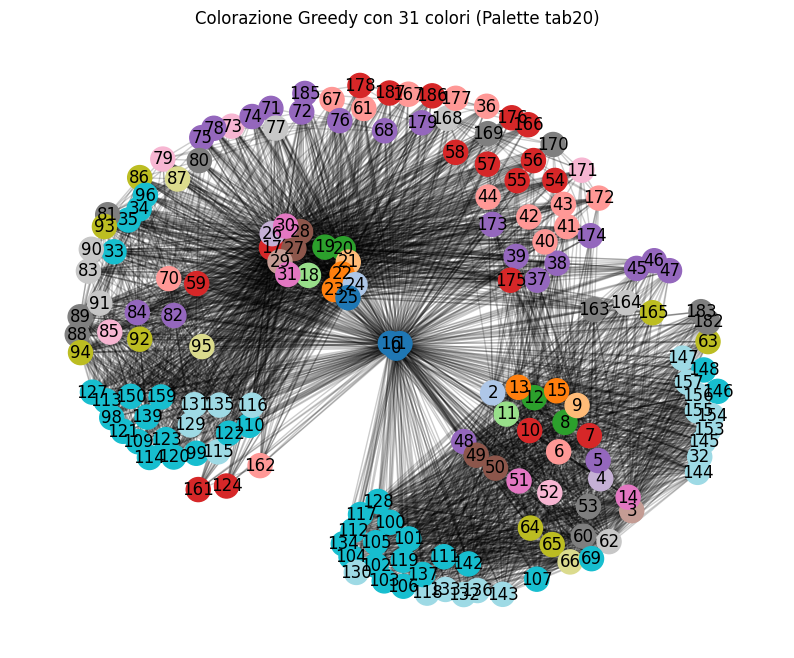

Data(x=[49, 1], edge_index=[2, 952], num_nodes=49, name='g9', num_edges_dimacs=952, num_edges_unique=476, declared_num_edges=952)
Name: g9
Number of nodes: 49
DIMACS edges: 476
PyG edge_index shape: torch.Size([2, 952])


Colorazione Greedy ci mette 11 colori
Conflitti:         0
Percentuale:       0.00%


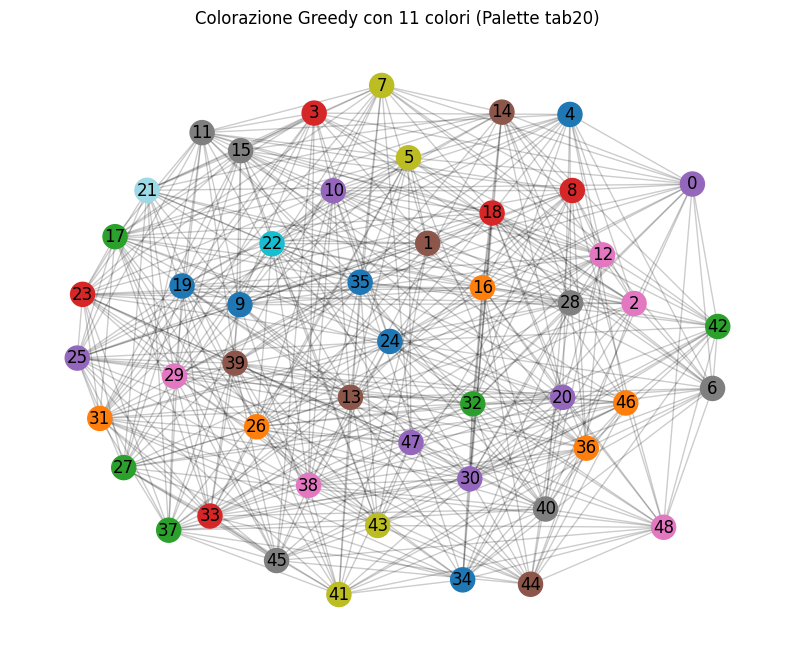

In [ ]:
# La libreria nx ha problemi nel plot di grafi con nodi isolati, questa variabile serve ad escluderli,
# In caso si voglia comunque visualizzare il grafo con tutti i nodi impostare a True
Show_All_Nodes = False

for idx, Grafo_Usato in enumerate(Grafi):

  data = read_dimacs_col(Grafo_Usato)
  G = to_networkx(data, to_undirected=True)
  if Grafo_Usato == "/content/g15.col" and not Show_All_Nodes:
    print(
    """
\nAttenzione, Il grafo 15 Presenta dei Nodi isolati, senza alcuna connessione con altri nodi\n
Pertanto verranno esclusi dal plot poiché la loro presenza renderebbe la visualizzazione del grafo complicata\n\n
In caso si voglia visualizzarli impostare la Variabile Show_All_Nodes a True
  """)

    G.remove_nodes_from(list(nx.isolates(G)))


  coloring = nx.greedy_color(G, strategy="DSATUR")
  num_colors_needed = max(coloring.values()) + 1
  palette = get_colors(num_colors_needed)
  node_colors = [palette[coloring[node]] for node in G.nodes()]

  Nodi_con_Archi_Uguali = []
  for i, j in G.edges:
      if coloring[i] == coloring[j]:
          Nodi_con_Archi_Uguali.append((i, j))

  print(f"\n\nColorazione Greedy ci mette {num_colors_needed} colori")
  print(f"Conflitti:         {len(Nodi_con_Archi_Uguali)}")
  print(f"Percentuale:       {(len(Nodi_con_Archi_Uguali)/len(G.edges))*100:.2f}%")
  assert len(Nodi_con_Archi_Uguali) == 0, "DSATUR non deve mai produrre conflitti: c'e' un bug nel conteggio o negli indici"

  plt.figure(figsize=(10, 8))
  pos = nx.kamada_kawai_layout(G)

  nx.draw_networkx_edges(G, pos, edgelist=Nodi_con_Archi_Uguali, width=0.6, edge_color="red",   alpha=0.5)
  nx.draw_networkx_edges(G, pos, alpha=0.2)
  nx.draw_networkx_nodes(G, pos, node_color=node_colors)
  nx.draw_networkx_labels(G, pos)



  plt.title(f"Colorazione Greedy con {num_colors_needed} colori (Palette tab20)")
  plt.axis('off')
  plt.show()

---
# Stima numero cromatico & Plot

---

Per stimare il numero cromatico di ciascun grafo riportiamo il numero minimo di
conflitti ottenuto (sul migliore dei seed) in funzione del numero di colori $k$.   
Il numero cromatico stimato $\chi$ è il più piccolo $k$ per cui il metodo trova
una colorazione con zero conflitti. Si tratta di una **stima algoritmica**, non
di una dimostrazione: l'assenza di conflitti per un dato $k$ prova che il grafo è
$k$-colorabile, ma un fallimento può dipendere
dall'ottimizzazione e non dall'impossibilità matematica.

Grafo 15: numero cromatico stimato -> Pair = None, SAGE = None
Grafo 9: numero cromatico stimato -> Pair = None, SAGE = 14


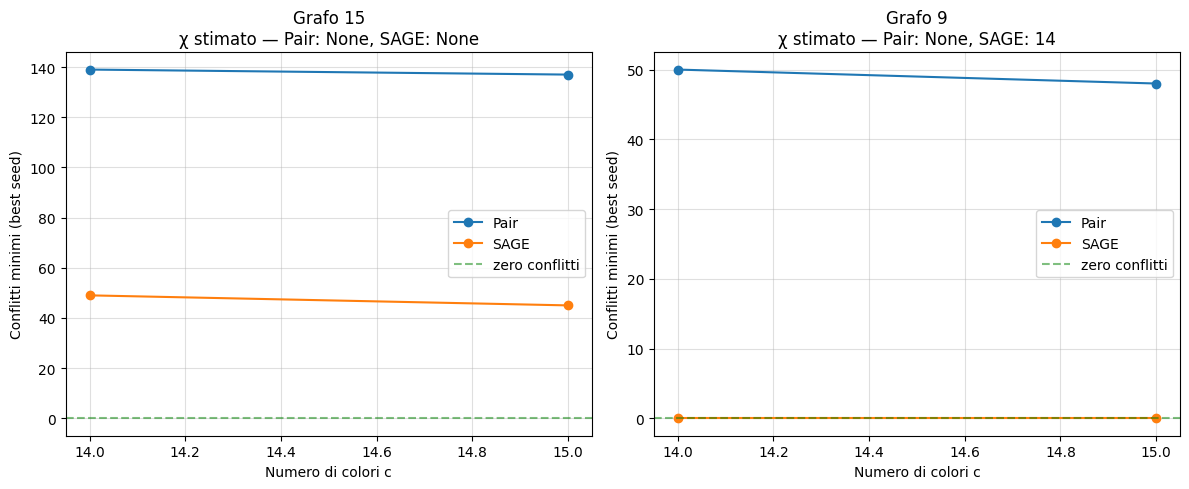

In [ ]:
fig, axes = plt.subplots(1, len(Statistiche_Per_Grafo),
                         figsize=(6 * len(Statistiche_Per_Grafo), 5), squeeze=False)

for ax_idx, (nome_grafo, stats) in enumerate(Statistiche_Per_Grafo.items()):
    ax = axes[0, ax_idx]
    chi_stimato = {}

    for modello in ["Pair", "SAGE"]:
        cs   = sorted(stats[modello].keys())
        # numero minimo di conflitti ottenuto sui vari seed, per ciascun c
        cmin = [min(stats[modello][c]) if len(stats[modello][c]) else float("nan")
                for c in cs]
        ax.plot(cs, cmin, marker="o", label=modello)

        # primo c con zero conflitti = numero cromatico stimato
        validi = [c for c in cs if len(stats[modello][c]) and min(stats[modello][c]) == 0]
        chi_stimato[modello] = min(validi) if validi else None

    ax.axhline(0, color="green", linestyle="--", alpha=0.5, label="zero conflitti")
    ax.set_title(f"{nome_grafo}\nχ stimato — Pair: {chi_stimato['Pair']}, "
                 f"SAGE: {chi_stimato['SAGE']}")
    ax.set_xlabel("Numero di colori c")
    ax.set_ylabel("Conflitti minimi (best seed)")
    ax.grid(True, alpha=0.4)
    ax.legend()

    print(f"{nome_grafo}: numero cromatico stimato -> "
          f"Pair = {chi_stimato['Pair']}, SAGE = {chi_stimato['SAGE']}")

plt.tight_layout()
plt.show()

---
# Our Model Plots
---

## Plot Del Grafo Colorato

In [ ]:
# Colorazione del Grafo con l'uso del numero di colori massimo impostato (in questo caso 15)

graph_plot(Pair_GNN,data)
graph_plot(SAGE_GNN,data)

## Plot delle Loss

Seed Numero 117:




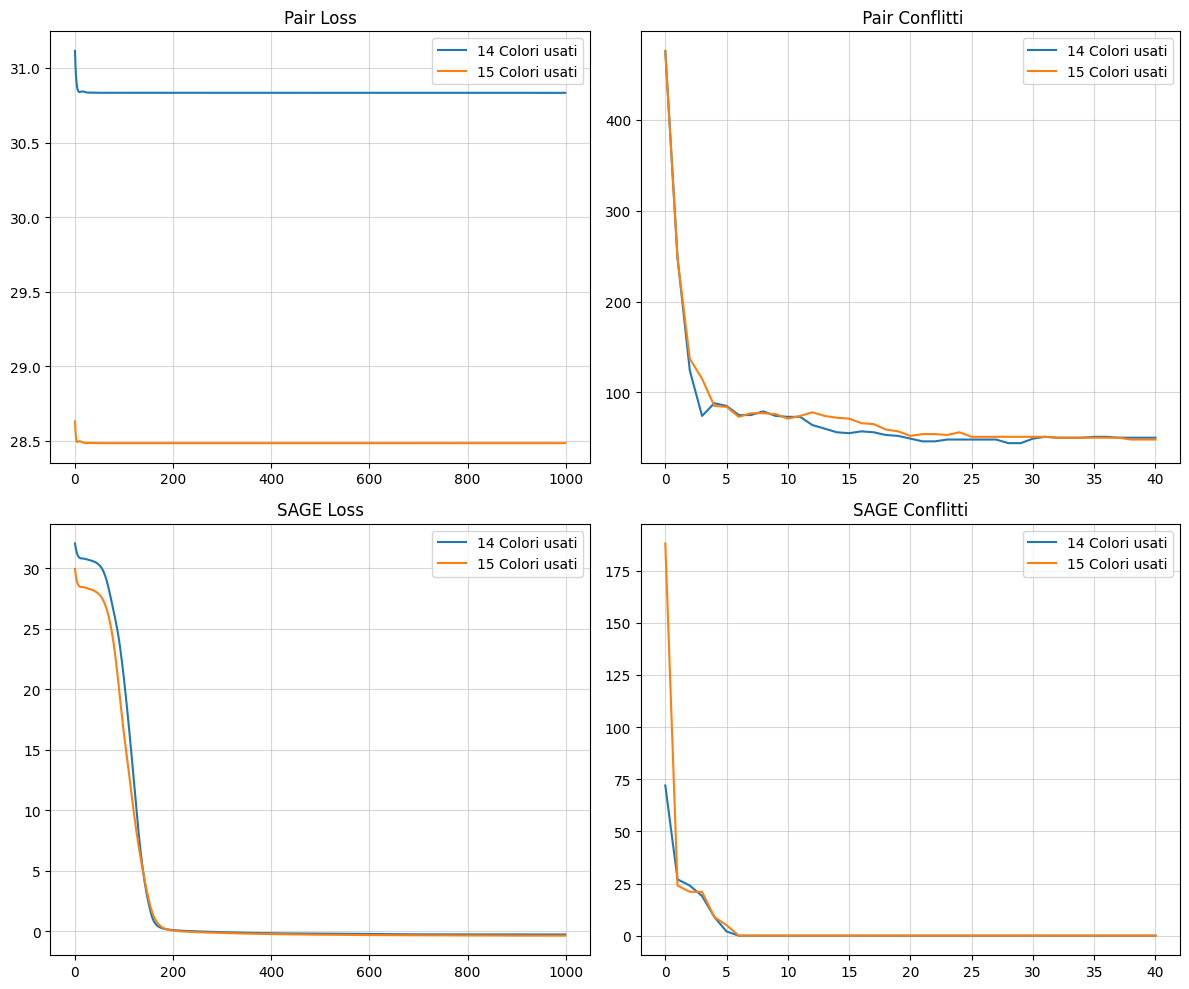

In [ ]:
keys = list(Plots_Per_Seed.keys())

Rand_Seed = keys[torch.randint(len(keys), (1,)).item()]
print(f"Seed Numero {Rand_Seed}:\n\n")


GNNTmp = Plots_Per_Seed[Rand_Seed]["Pair"]
SAGETmp = Plots_Per_Seed[Rand_Seed]["SAGE"]

GNN_Loss = GNNTmp["Loss"]
GNN_Conf = GNNTmp["Conflitti"]
SAGE_Loss = SAGETmp["Loss"]
SAGE_Conf = SAGETmp["Conflitti"]

Titles = ["Pair Loss", " Pair Conflitti", "SAGE Loss", "SAGE Conflitti"]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, M in enumerate([GNN_Loss, GNN_Conf, SAGE_Loss, SAGE_Conf]):
    ax = axes[i // 2, i % 2]

    for idx,serie in enumerate(M):
        ax.plot(serie,
                label = f"{idx + min_colori} Colori usati")

    ax.set_title(f"{Titles[i]}")
    ax.legend()
    ax.grid("on", alpha = 0.5)


plt.tight_layout()
plt.show()

# **Discussione dei Risultati**
---

L'analisi dei risultati sperimentali consente di approfondire la dinamica di apprendimento dei modelli e di rispondere in modo critico ai quesiti fondamentali che definiscono l'approccio proposto.

1. **Il metodo converge sempre?**
No, il metodo non garantisce una convergenza globale assoluta. Come evidenziato dai test sperimentali, l'architettura **SAGEGNN** mostra una convergenza progressiva e stabile: nel caso del grafo $g_9$, il valore della loss, ed in particolare il suo segno, non costituisce un criterio di validità della colorazione: poiché la loss combina il termine di Potts con un termine entropico massimizzato, essa può assumere valori negativi anche in
presenza di conflitti residui. L'unico indicatore decisivo è il numero di conflitti hard ottenuto dopo l'argmax.   
Con learning rate allineato tra le due reti (1e-3), il comportamento di **PairGNN** cambia rispetto a una configurazione con lr inferiore: la rete non resta intrappolata, ma riduce i conflitti in modo monotono (su g15, da 879 a 143).   
Il divario residuo con SAGEGNN non è quindi un fallimento di convergenza, ma una minore efficienza nello sfruttare i colori disponibili. Questo suggerisce che gran parte del divario osservato in configurazioni precedenti fosse imputabile al learning rate, e solo in parte alla differenza architetturale (profondità e meccanismo di aggregazione). Tuttavia, ricordiamo che GCNConv, per via dell'aggregazione mediata e normalizzata su tre layer, è più esposta all'over-smoothing rispetto alla concatenazione di SAGEConv, ma l'effetto è graduale, non un blocco.
Inoltre, è fondamentale evidenziare che la convergenza della loss non equivale matematicamente all'azzeramento dei conflitti. Anche in presenza di una loss decrescente, l'applicazione finale dell'operatore discreto $\text{argmax}$ può far emergere conflitti latenti, poiché la rete ottimizza probabilità nello spazio continuo mentre il problema richiede un'assegnazione netta (*hard*).

2. **Quanto dipende dall’inizializzazione casuale?**
Il metodo mostra una dipendenza critica dall'inizializzazione dei parametri. A ogni iterazione del ciclo esterno, sia i pesi dei layer convoluzionali sia i vettori di `torch.nn.Embedding` associati ai nodi vengono inizializzati casualmente.
Poiché la superficie di loss associata al problema del *graph coloring* è altamente non convessa, essa presenta un numero esponenziale di minimi locali corrispondenti a colorazioni parziali o errate. Di conseguenza, il punto di partenza nello spazio dei parametri determina il bacino di attrazione verso cui l'ottimizzatore si muoverà.
Per quantificare la dipendenza dall'inizializzazione abbiamo ripetuto l'ottimizzazione su diversi $n$ seed indipendenti per ciascun valore di $k$ e, per ciscuno, viene riportato il numero minimo di conflitti, la media con deviazione standard e la frazione di run che raggiungono zero conflitti. Pertanto, zero conflitti ottenuti in un singolo run non garantisce l'assoluta affidabilità del modello per quel valore di $k$: potrebbe trattarsi di un'inizializzazione fortunata. Simmetricamente, il fallimento non certifica che il grafo non sia $k$-colorabile, ma indica semplicemente che l'ottimizzatore è rimasto bloccato in un minimo locale sub-ottimale. Per tale ragione, il valore individuato rimane una stima algoritmica e non una dimostrazione formale: non è escluso che il reale numero cromatico del grafo $g_9$ possa essere inferiore a $12$.

3. **Quali valori di $c$ risultano sufficienti?**
La sufficienza del numero di colori $c$ (o $k$) è strettamente legata alla topologia e alla complessità del singolo grafo:

* **Grafo $g_9$** , con $49$ nodi e $476$ archi: la rete *SAGEGNN* individua una colorazione valida (zero conflitti) a partire da $k = 12$. Questo valore è da confrontare con il risultato dell'algoritmo euristico classico DSATUR che è di $k=11$. Si tratta di un riscontro estremamente positivo, in quanto un modello neurale non supervisionato è riuscito ad avvicinarsi alla soluzione di un'euristica combinatoria deterministica. Nell'intervallo $k \in [5, 11]$ si osserva una chiara fase di transizione: la loss diminuisce, ma i colori non sono ancora sufficienti a sciogliere i conflitti residui.
* **Grafo $g_{15}$**, in cui si hanno $188$ nodi e un elevata densità di archi: il problema si rivela notevolmente più complesso. Per g15 l'intervallo $k\in [2, 15]$ è insufficiente: nessun valore testato produce zero conflitti, per nessuna delle due reti.   
A $k=15$ il miglior risultato (SAGE, 40 conflitti minimi) lascia ancora una frazione non trascurabile di archi in conflitto e il numero cromatico reale è $> 15$, per stimarlo occorre estendere la scansione a valori di $k$ più alti.    
L'andamento dei conflitti minimi di SAGE è ancora in discesa regolare a fine intervallo: la riduzione di circa 8-10 conflitti per colore aggiuntivo suggerisce che servano parecchi colori in più per azzerarli, ma è un'estrapolazione, non una misura.

4. **Ci sono casi in cui la loss diminuisce ma rimangono conflitti?**
Sì, questo fenomeno rappresenta una delle dinamiche più interessanti osservate. La discrepanza è di natura strutturale: la *loss function* è una metrica continua e differenziabile calcolata sui logit in uscita dal Softmax, mentre il *numero di conflitti* è una metrica discreta calcolata a valle dell'operatore $\text{argmax}$.
Dall'analisi congiunta dei grafici *Loss vs Epoch* e *Conflitti vs Epoch*, si nota come la loss decresca in modo fluido sin dalle prime epoche, mentre i conflitti discreti rimangono costanti o subiscono temporanei incrementi. Ciò si verifica quando la rete riduce l'errore distribuendo la probabilità in modo quasi uniforme su più canali di colore per evitare penalità drastiche. In questa fase la Softmax è "morbida" (ampia varianza), e minime oscillazioni nei logit modificano l'indice massimo dell'output, rendendo l'assegnazione tramite $\text{argmax}$ altamente instabile.
Inoltre, il bilanciamento tra i pesi impostati, $\lambda_H = 1.0$ per la Potts loss e $\lambda_E = 1.2$ per l'entropia, fa sì che il termine entropico eserciti una pressione dominante: in contesti di forte polarizzazione dei nodi "facili", la loss complessiva può assumere valori negativi anche in presenza di archi residui in conflitto. Di conseguenza, la sola loss non costituisce una metrica sufficiente per valutare la validità della colorazione, lasciando al computo dei conflitti *hard* il ruolo di unico indicatore discriminante.  
$g15$ è l'esempio diretto di questa dinamica: la loss continua decresce per tutto il training, ma la frazione di run valide resta 0% a ogni k testato. La loss bassa o negativa non si traduce in colorazione valida, confermando che l'unico indicatore affidabile è il conteggio dei conflitti hard.


5. **Quali sono i limiti del metodo?**
Affrontare un problema NP-completo utilizzando le Graph Neural Networks (GNN) differenziabili ci mette inevitabilmente di fronte a delle limitazioni strutturali e operative che è importante contestualizzare.

* La prima difficoltà evidente è la forte sensibilità del modello all'architettura scelta, questo implica una mancanza di garanzie teoriche di convergenza. Lo abbiamo visto chiaramente nel divario di prestazioni tra SAGEGNN e PairGNN, infatti, pur avendo allineato il learning rate per isolare l'effetto dell'architettura, le due reti differiscono ancora per il tipo di convoluzione e per la profondità (3 layer contro 2).

* Un altro problema si ha con l'over-smoothing. Nella colorazione dei grafi è cruciale preservare l'eterogeneità tra i nodi adiacenti e per evitare che i nodi diventino indistinguibili tra loro, siamo costretti a mantenere reti poco profonde, limitandoci a 2 o 3 layer. Questa restrizione, per quanto necessaria, impedisce di catturare e propagare le relazioni strutturali a lungo raggio nei grafi più complessi.

* Ai precedenti punti si aggiunge uno scollamento di fondo tra la natura del modello e quella del task. Ottimizzare una funzione di costo continua (come avviene nel deep learning) non assicura in alcun modo che il suo minimo globale vada a coincidere perfettamente con lo "zero" del problema combinatorio, che è strettamente discreto.    
Di conseguenza, dobbiamo accettare una certa incompletezza algoritmica: il nostro modello si comporta a tutti gli effetti come un'euristica di ricerca. Se non riesce a trovare una configurazione valida utilizzando un numero k di colori, attesta solo che il processo di ottimizzazione locale è fallito e non è riuscito a sfuggire a un vicolo cieco.

* Tutte queste dinamiche culminano nel problema della scalabilità. Come abbiamo toccato con mano passando da grafi di dimensione g9 a g15, quando il grafo cresce in dimensione e densità, lo spazio delle possibili configurazioni esplode a livello combinatorio. Questo trasforma la superficie della loss in un paesaggio estremamente accidentato, denso di minimi locali che intrappolano il gradiente e rendono molto difficile l'ottimizzazione.

6. **Quali miglioramenti sarebbero possibili?**
Per il miglioramento del progetto si potrebbe intervenire in diversi ambiti, partendo da alcune modifiche all'algoritmo. Anche se sarebbe utile aggiungere una fase di post-processing alla fine del training, dopo aver provato la sua implementazione abbiamo notato che la colorazione subiva un aumento significativo dei conflitti, soprattutto con il grafo $g_{15}$, e quindi abbiamo deciso di rimuoverla come funzione.  
Invece, per evitare l'instabilità dell'argmax, potremmo far decrescere durante il training sia la temperatura della softmax sia il peso dell'entropia.   
In questo modo la rete sarebbe libera di esplorare all'inizio, ma verrebbe spinta a scegliere un colore preciso nelle ultime epoche. Per ridurre la sensibilità all'inizializzazione dei pesi, infine, converrebbe integrare i restart multipli direttamente nel codice, salvando in automatico solo la run venuta meglio.
Dal punto di vista della struttura e dei test, per superare il problema dell'over-smoothing e usare reti più profonde si potrebbero testare soluzioni come le connessioni skip o i layer attentivi (GAT), che evitano di "appiattire" i nodi vicini. Per quanto riguarda gli esperimenti, nel caso del grafo $g_{15}$​
conviene aumentare il numero di colori provati fino a circa 30, così da trovare il valore minimo reale che azzera i conflitti. Infine, per fare un confronto equo tra 'PairGNN' e 'SAGEGNN', servirebbe un ablation study impostando per entrambe lo stesso learning rate e la stessa profondità.

Tutti questi accorgimenti non cambierebbero la natura del metodo, ma lo renderebbero molto più robusto e preciso anche sui grafi più complessi.
